# Sections 2–5: Exploratory Data Analysis, Detection Methods, Discovery Trends & Missing Data

## Overview
This notebook conducts a deep empirical and statistical investigation into the NASA Exoplanet Archive (`cleaned_exoplanet_data.csv`). It directly answers **four core analytical pillars**:

1. **Section 2: Exploratory Data Analysis (EDA)**
   * Physical properties: Planet mass, radius, density, and empirical Mass-Radius relations.
   * Orbital properties: Orbital period, semi-major axis, and Kepler's Third Law.
   * Exoplanet demographics: Population distribution and the **Fulton Radius Valley** (~1.5–2.0 $R_\oplus$).
   * Planet-star interactions: Stellar metallicity vs. giant planet occurrence, stellar temperature vs. insolation, and multi-planet architectures.

2. **Section 3: Detection Method Analysis**
   * Quantitative comparison of the two dominant detection techniques: **Transit** vs. **Radial Velocity (RV)**.
   * Statistical hypothesis testing (**Mann-Whitney U** and **Kolmogorov-Smirnov** two-sample tests) on physical and orbital distributions.
   * Astrophysical selection biases: Geometric transit probability ($P_{tr} \propto R_*/a$) and RV Doppler semi-amplitude ($K \propto M_p \sin i / \sqrt{a}$).

3. **Section 4: Discovery Trends**
   * Historical timeline of discoveries (1992–2026): From the first pulsar planets and 51 Pegasi b to the space-telescope era.
   * Space mission revolutions: Ground-based RV $\rightarrow$ CoRoT $\rightarrow$ Kepler/K2 $\rightarrow$ TESS $\rightarrow$ Gaia $\rightarrow$ JWST.
   * Shift in detected planetary regimes over time (Hot Jupiters $\rightarrow$ Sub-Neptunes / Super-Earths).
   * Observational horizon: Evolution of distance and stellar magnitude over time.

4. **Section 5: Missing-Data Analysis**
   * Missingness profile across planetary, orbital, and stellar parameters.
   * Cross-method missingness: Why RV planets lack radii while Transit planets often lack dynamical masses.
   * Cross-era missingness: Impact of modern astrometric surveys (Gaia) on completing stellar parameters.
   * Missingness correlation matrix and astrophysical explanations.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

os.makedirs('figures', exist_ok=True)
print("Libraries imported and plotting configured.")


Libraries imported and plotting configured.


## Load Curated Dataset
We load `cleaned_exoplanet_data.csv` generated in Section 1.


In [2]:
df = pd.read_csv('cleaned_exoplanet_data.csv')
print(f"Loaded {df.shape[0]:,} exoplanets across {df.shape[1]} features.")
df[['pl_name', 'discoverymethod', 'disc_year', 'planet_type', 'pl_bmasse', 'pl_rade', 'pl_orbper']].head(5)


Loaded 6,445 exoplanets across 36 features.


,pl_name,discoverymethod,disc_year,planet_type,pl_bmasse,pl_rade,pl_orbper
0,HD 2039 b,Radial Velocity,2002,Gas Giant,1999.1507,12.700000,1120.000000
1,HAT-P-8 b,Transit,2008,Hot Jupiter,406.8224,15.692600,3.076340
2,K2-43 b,Transit,2016,Neptune-like,18.5000,4.510000,3.471149
3,Kepler-1753 b,Transit,2021,Sub-Neptune,5.5900,2.226781,16.004601
4,Kepler-1176 b,Transit,2016,Sub-Neptune,6.5700,2.450000,24.173858


---
# Section 2: Exploratory Data Analysis (EDA)

### 2.1 Physical Properties: Mass, Radius, Density, and Mass-Radius Scaling
We analyze the distribution of planet sizes, masses, and bulk densities across orders of magnitude. In particular, we inspect:
* The bi-modal distribution of small planet radii showing the **Fulton Gap (Radius Valley)** between 1.5 and 2.0 $R_\oplus$, separating rocky Super-Earths from volatile-rich Sub-Neptunes.
* The empirical Mass-Radius relation and how bulk density transitions from dense terrestrial compositions to puffy gas giants.


<>:19: SyntaxWarning: invalid escape sequence '\,'
<>:28: SyntaxWarning: invalid escape sequence '\,'
<>:29: SyntaxWarning: invalid escape sequence '\,'
<>:30: SyntaxWarning: invalid escape sequence '\,'
<>:31: SyntaxWarning: invalid escape sequence '\,'
<>:19: SyntaxWarning: invalid escape sequence '\,'
<>:28: SyntaxWarning: invalid escape sequence '\,'
<>:29: SyntaxWarning: invalid escape sequence '\,'
<>:30: SyntaxWarning: invalid escape sequence '\,'
<>:31: SyntaxWarning: invalid escape sequence '\,'
C:\Users\DELL\AppData\Local\Temp\ipykernel_25332\2554077364.py:19: SyntaxWarning: invalid escape sequence '\,'
  ax.axvline(1.0, color='forestgreen', linestyle='--', linewidth=2, label='Earth ($1.0\,R_\\oplus$)')
C:\Users\DELL\AppData\Local\Temp\ipykernel_25332\2554077364.py:28: SyntaxWarning: invalid escape sequence '\,'
  ax.axvline(5.51, color='forestgreen', linestyle='--', linewidth=2, label='Earth ($5.51\,\\text{g/cm}^3$)')
C:\Users\DELL\AppData\Local\Temp\ipykernel_25332\25540773

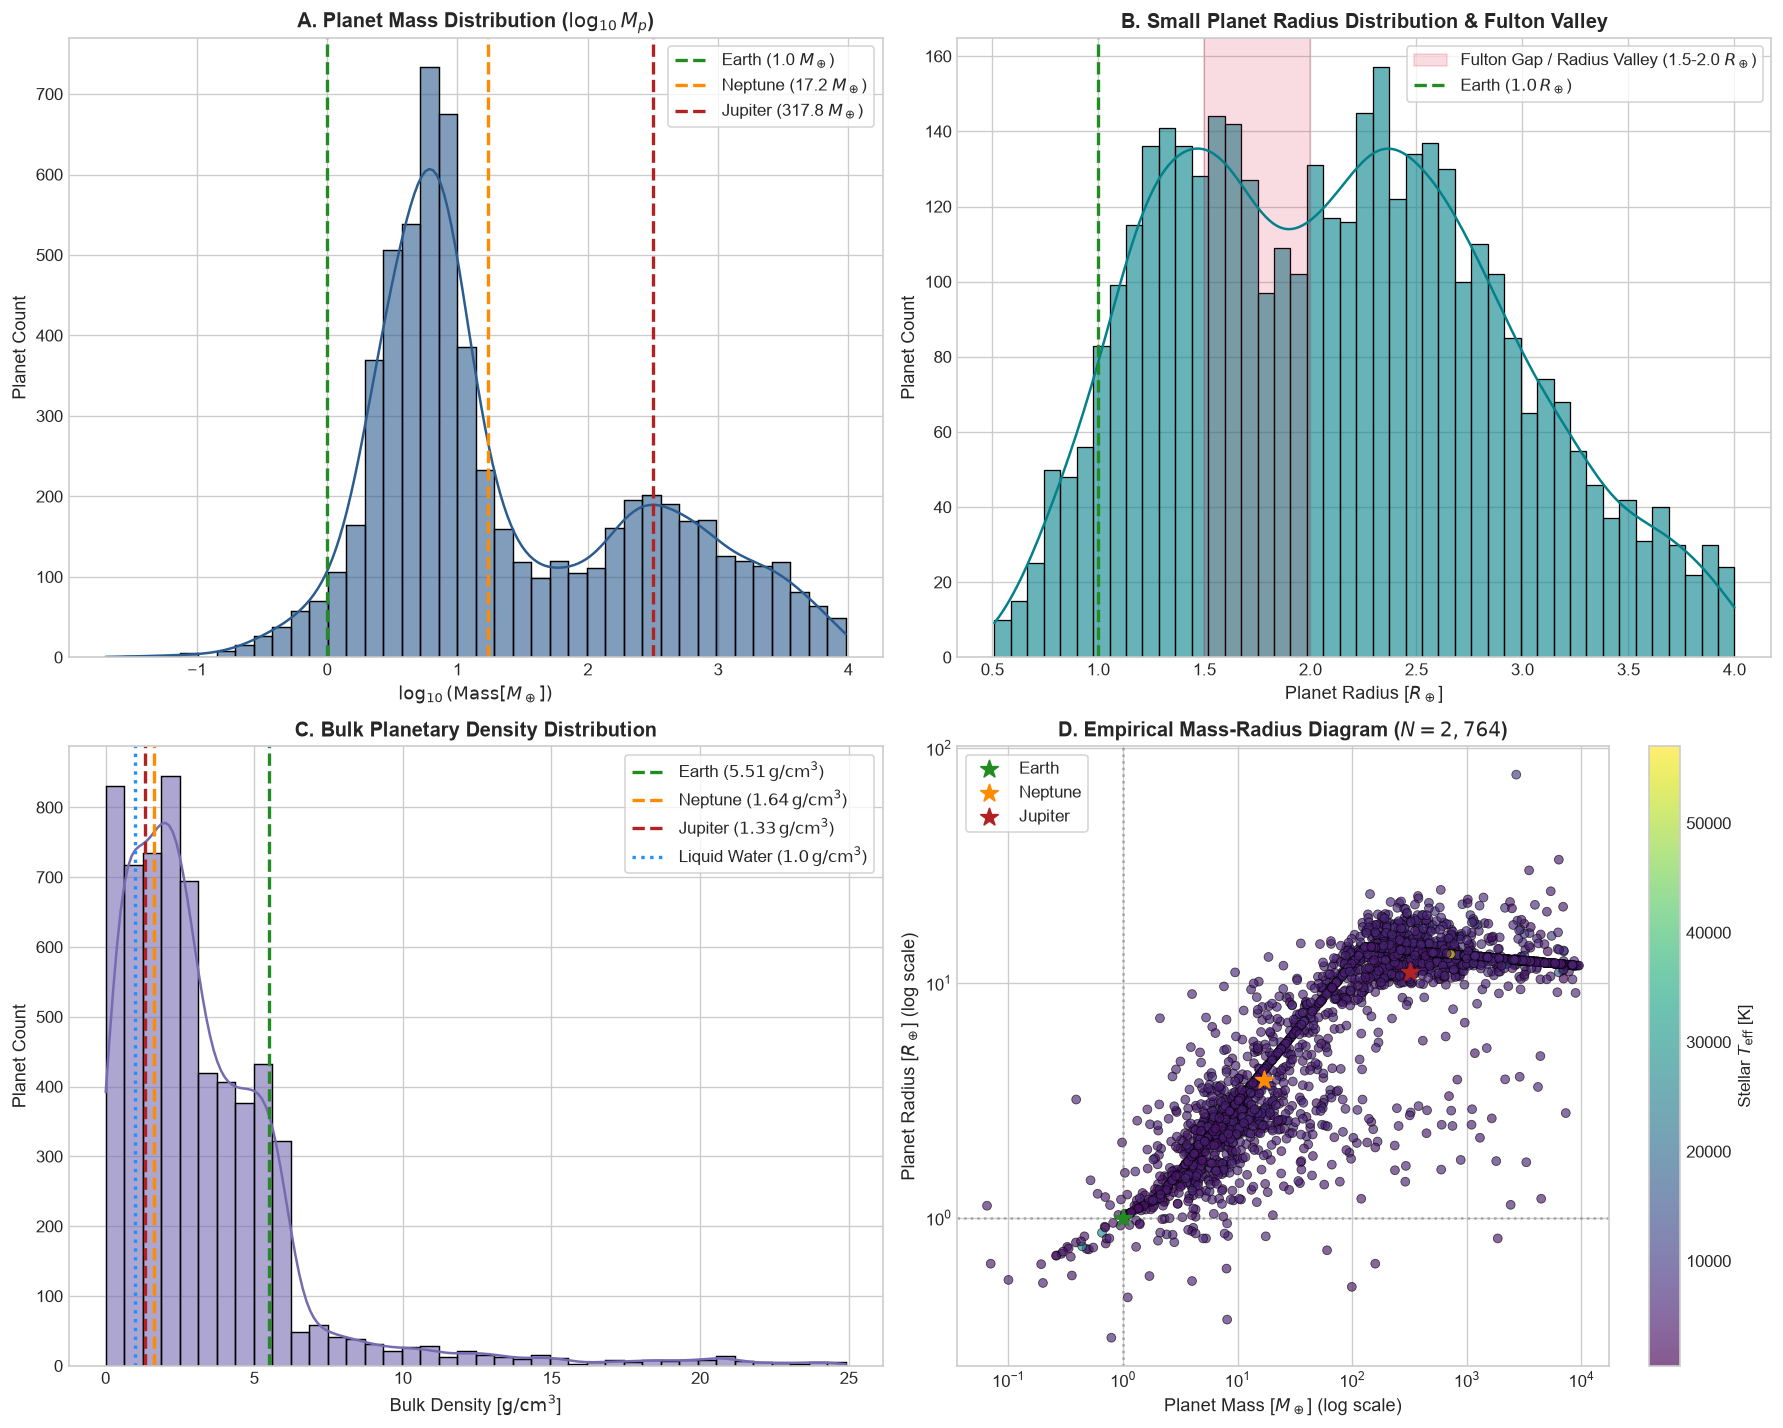

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Planet Mass Distribution (Empirical vs Model-Derived)
ax = axes[0, 0]
sns.histplot(df['log_pl_bmasse'].dropna(), bins=40, kde=True, color='#2b5c8f', ax=ax, edgecolor='black', alpha=0.6)
ax.axvline(np.log10(1.0), color='forestgreen', linestyle='--', linewidth=2, label='Earth (1.0 $M_\\oplus$)')
ax.axvline(np.log10(17.15), color='darkorange', linestyle='--', linewidth=2, label='Neptune (17.2 $M_\\oplus$)')
ax.axvline(np.log10(317.8), color='firebrick', linestyle='--', linewidth=2, label='Jupiter (317.8 $M_\\oplus$)')
ax.set_title('A. Planet Mass Distribution ($\\log_{10} M_p$)', fontsize=12, fontweight='bold')
ax.set_xlabel('$\\log_{10}(\\text{Mass} [M_\\oplus])$', fontsize=11)
ax.set_ylabel('Planet Count', fontsize=11)
ax.legend(frameon=True)

# 2. Planet Radius Distribution & The Fulton Gap
ax = axes[0, 1]
small_planets = df[df['pl_rade'].between(0.5, 4.0)]['pl_rade']
sns.histplot(small_planets, bins=45, kde=True, color='#02818a', ax=ax, edgecolor='black', alpha=0.6)
ax.axvspan(1.5, 2.0, color='crimson', alpha=0.15, label='Fulton Gap / Radius Valley (1.5-2.0 $R_\\oplus$)')
ax.axvline(1.0, color='forestgreen', linestyle='--', linewidth=2, label='Earth ($1.0\,R_\\oplus$)')
ax.set_title('B. Small Planet Radius Distribution & Fulton Valley', fontsize=12, fontweight='bold')
ax.set_xlabel('Planet Radius [$R_\\oplus$]', fontsize=11)
ax.set_ylabel('Planet Count', fontsize=11)
ax.legend(frameon=True)

# 3. Bulk Density Distribution
ax = axes[1, 0]
sns.histplot(df[df['pl_dens'] < 25]['pl_dens'].dropna(), bins=40, kde=True, color='#756bb1', ax=ax, edgecolor='black', alpha=0.6)
ax.axvline(5.51, color='forestgreen', linestyle='--', linewidth=2, label='Earth ($5.51\,\\text{g/cm}^3$)')
ax.axvline(1.64, color='darkorange', linestyle='--', linewidth=2, label='Neptune ($1.64\,\\text{g/cm}^3$)')
ax.axvline(1.33, color='firebrick', linestyle='--', linewidth=2, label='Jupiter ($1.33\,\\text{g/cm}^3$)')
ax.axvline(1.0, color='dodgerblue', linestyle=':', linewidth=2, label='Liquid Water ($1.0\,\\text{g/cm}^3$)')
ax.set_title('C. Bulk Planetary Density Distribution', fontsize=12, fontweight='bold')
ax.set_xlabel('Bulk Density [$\\text{g/cm}^3$]', fontsize=11)
ax.set_ylabel('Planet Count', fontsize=11)
ax.legend(frameon=True)

# 4. Mass-Radius Diagram (Empirical Measurements Only)
ax = axes[1, 1]
empirical = df[df['is_measured_mass'] & df['pl_rade'].notna() & df['pl_bmasse'].notna()].copy()
scatter = ax.scatter(empirical['pl_bmasse'], empirical['pl_rade'], c=empirical['st_teff'], cmap='viridis',
                     alpha=0.65, edgecolors='black', linewidth=0.5, s=28)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Stellar $T_{\\text{eff}}$ [K]', fontsize=10)
ax.set_xscale('log')
ax.set_yscale('log')
ax.axvline(1.0, color='gray', linestyle=':', alpha=0.6)
ax.axhline(1.0, color='gray', linestyle=':', alpha=0.6)
ax.scatter([1.0], [1.0], color='forestgreen', s=120, marker='*', zorder=5, label='Earth')
ax.scatter([17.15], [3.88], color='darkorange', s=120, marker='*', zorder=5, label='Neptune')
ax.scatter([317.8], [11.21], color='firebrick', s=120, marker='*', zorder=5, label='Jupiter')
ax.set_title('D. Empirical Mass-Radius Diagram ($N = 2,764$)', fontsize=12, fontweight='bold')
ax.set_xlabel('Planet Mass [$M_\\oplus$] (log scale)', fontsize=11)
ax.set_ylabel('Planet Radius [$R_\\oplus$] (log scale)', fontsize=11)
ax.legend(frameon=True, loc='upper left')

plt.tight_layout()
plt.savefig('figures/02_eda_physical_properties.png', dpi=300)
plt.show()


### 2.2 Orbital Architectures & Kepler's Laws
We evaluate the distribution of orbital periods $P$, semi-major axes $a$, and check consistency with Kepler's Third Law ($P^2 \propto a^3 / M_*$). We also inspect the **Period-Radius plane** to visualize the **Sub-Jovian Desert ("Neptune Desert")**—a notable absence of intermediate-sized planets at extremely short orbital periods ($P < 3-5$ days).


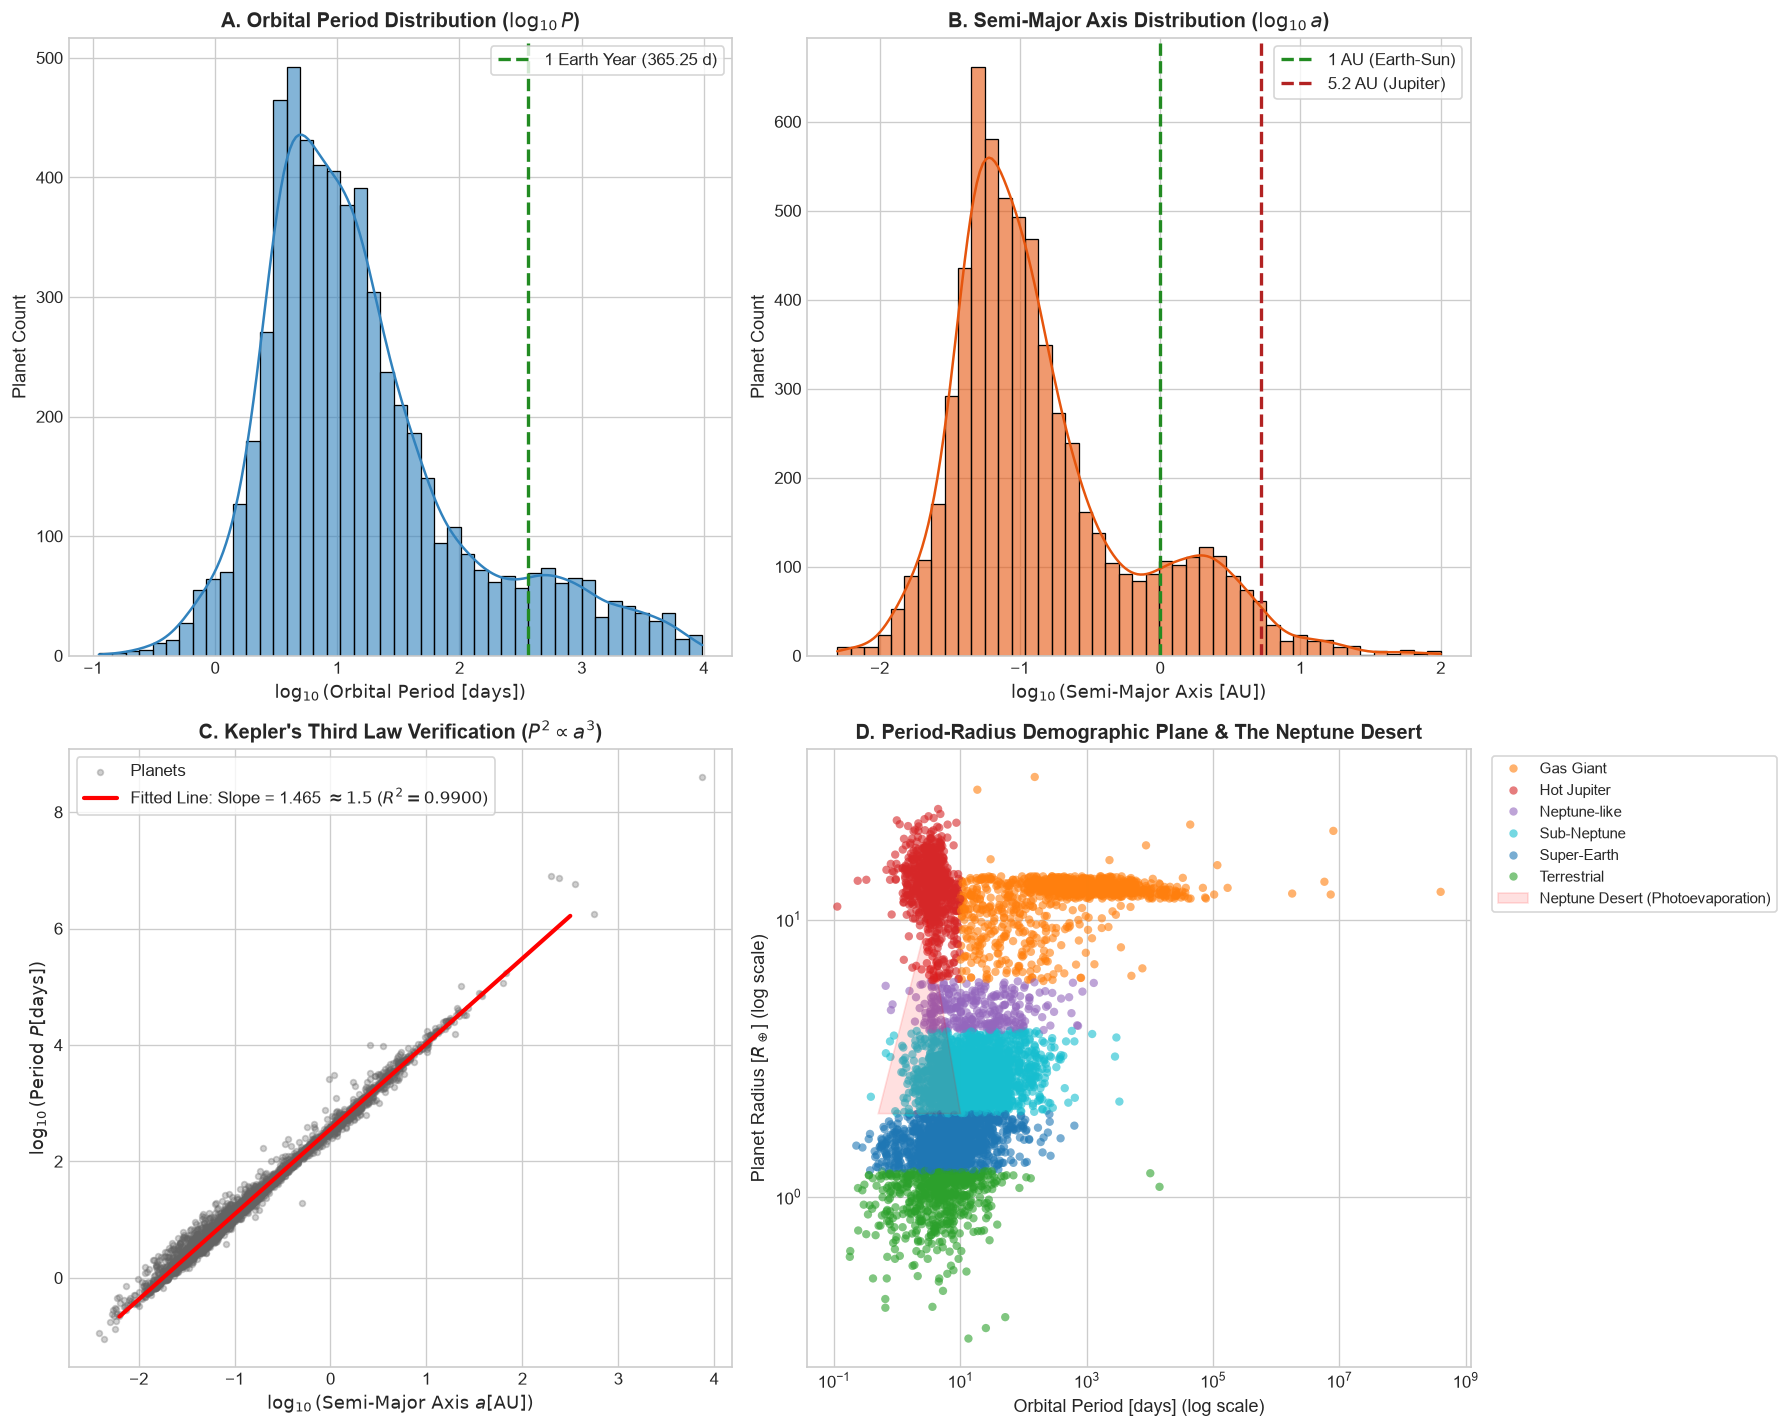

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Orbital Period Distribution
ax = axes[0, 0]
valid_p = df[df['pl_orbper'].between(0.1, 10000)]['pl_orbper']
sns.histplot(np.log10(valid_p), bins=45, kde=True, color='#3182bd', ax=ax, edgecolor='black', alpha=0.6)
ax.axvline(np.log10(365.25), color='forestgreen', linestyle='--', linewidth=2, label='1 Earth Year (365.25 d)')
ax.set_title('A. Orbital Period Distribution ($\\log_{10} P$)', fontsize=12, fontweight='bold')
ax.set_xlabel('$\\log_{10}(\\text{Orbital Period [days]})$', fontsize=11)
ax.set_ylabel('Planet Count', fontsize=11)
ax.legend(frameon=True)

# 2. Semi-Major Axis Distribution
ax = axes[0, 1]
valid_a = df[df['pl_orbsmax'].between(0.005, 100)]['pl_orbsmax']
sns.histplot(np.log10(valid_a), bins=45, kde=True, color='#e6550d', ax=ax, edgecolor='black', alpha=0.6)
ax.axvline(np.log10(1.0), color='forestgreen', linestyle='--', linewidth=2, label='1 AU (Earth-Sun)')
ax.axvline(np.log10(5.2), color='firebrick', linestyle='--', linewidth=2, label='5.2 AU (Jupiter)')
ax.set_title('B. Semi-Major Axis Distribution ($\\log_{10} a$)', fontsize=12, fontweight='bold')
ax.set_xlabel('$\\log_{10}(\\text{Semi-Major Axis [AU]})$', fontsize=11)
ax.set_ylabel('Planet Count', fontsize=11)
ax.legend(frameon=True)

# 3. Kepler's Third Law Verification (log P vs log a)
ax = axes[1, 0]
valid_kepler = df.dropna(subset=['log_pl_orbsmax', 'log_pl_orbper', 'st_mass']).copy()
slope, intercept, r_value, p_value, std_err = stats.linregress(valid_kepler['log_pl_orbsmax'], valid_kepler['log_pl_orbper'])
ax.scatter(valid_kepler['log_pl_orbsmax'], valid_kepler['log_pl_orbper'], alpha=0.3, s=12, color='#636363', label='Planets')
x_vals = np.linspace(-2.2, 2.5, 100)
ax.plot(x_vals, slope * x_vals + intercept, color='red', linewidth=2.5,
        label=f'Fitted Line: Slope = {slope:.3f} $\\approx 1.5$ ($R^2={r_value**2:.4f}$)')
ax.set_title("C. Kepler's Third Law Verification ($P^2 \\propto a^3$)", fontsize=12, fontweight='bold')
ax.set_xlabel('$\\log_{10}(\\text{Semi-Major Axis } a [\\text{AU}])$', fontsize=11)
ax.set_ylabel('$\\log_{10}(\\text{Period } P [\\text{days}])$', fontsize=11)
ax.legend(frameon=True)

# 4. Period-Radius Plane: The Sub-Jovian (Neptune) Desert
ax = axes[1, 1]
valid_pr = df.dropna(subset=['pl_orbper', 'pl_rade', 'planet_type'])
palette = {'Terrestrial': '#2ca02c', 'Super-Earth': '#1f77b4', 'Sub-Neptune': '#17becf',
           'Neptune-like': '#9467bd', 'Gas Giant': '#ff7f0e', 'Hot Jupiter': '#d62728', 'Unknown': 'gray'}
sns.scatterplot(data=valid_pr, x='pl_orbper', y='pl_rade', hue='planet_type', palette=palette,
                alpha=0.6, s=25, ax=ax, edgecolor='none')
ax.set_xscale('log')
ax.set_yscale('log')
# Mark the Neptune desert
desert_x = [0.5, 3.0, 10.0, 0.5]
desert_y = [2.0, 10.0, 2.0, 2.0]
ax.fill(desert_x, desert_y, color='red', alpha=0.12, label='Neptune Desert (Photoevaporation)')
ax.set_title('D. Period-Radius Demographic Plane & The Neptune Desert', fontsize=12, fontweight='bold')
ax.set_xlabel('Orbital Period [days] (log scale)', fontsize=11)
ax.set_ylabel('Planet Radius [$R_\\oplus$] (log scale)', fontsize=11)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, fontsize=9)

plt.tight_layout()
plt.savefig('figures/02_eda_orbital_properties.png', dpi=300)
plt.show()


### 2.3 Relationships with Host-Star Properties
We test two foundational astrophysical relationships:
1. **The Giant Planet-Metallicity Correlation** (Fischer & Valenti 2005): Giant planets ($M_p > 100\,M_\oplus$) form predominantly around metal-rich stars ($[\text{Fe/H}] > 0$), supporting the Core Accretion model of planet formation.
2. **Stellar Temperature vs. Planetary Insolation**: Illustrating where planets sit relative to stellar flux and the Habitable Zone ($0.25 < S < 1.75\,S_\oplus$).


<>:21: SyntaxWarning: invalid escape sequence '\,'
<>:21: SyntaxWarning: invalid escape sequence '\,'
C:\Users\DELL\AppData\Local\Temp\ipykernel_25332\1683662135.py:21: SyntaxWarning: invalid escape sequence '\,'
  ax.axvspan(0.35, 1.75, color='green', alpha=0.18, label='Empirical Habitable Zone ($0.35 - 1.75\,S_\\oplus$)')
C:\Users\DELL\AppData\Local\Temp\ipykernel_25332\1683662135.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=met_df, x='planet_type', y='st_met', palette='Set3', ax=ax, fliersize=2)


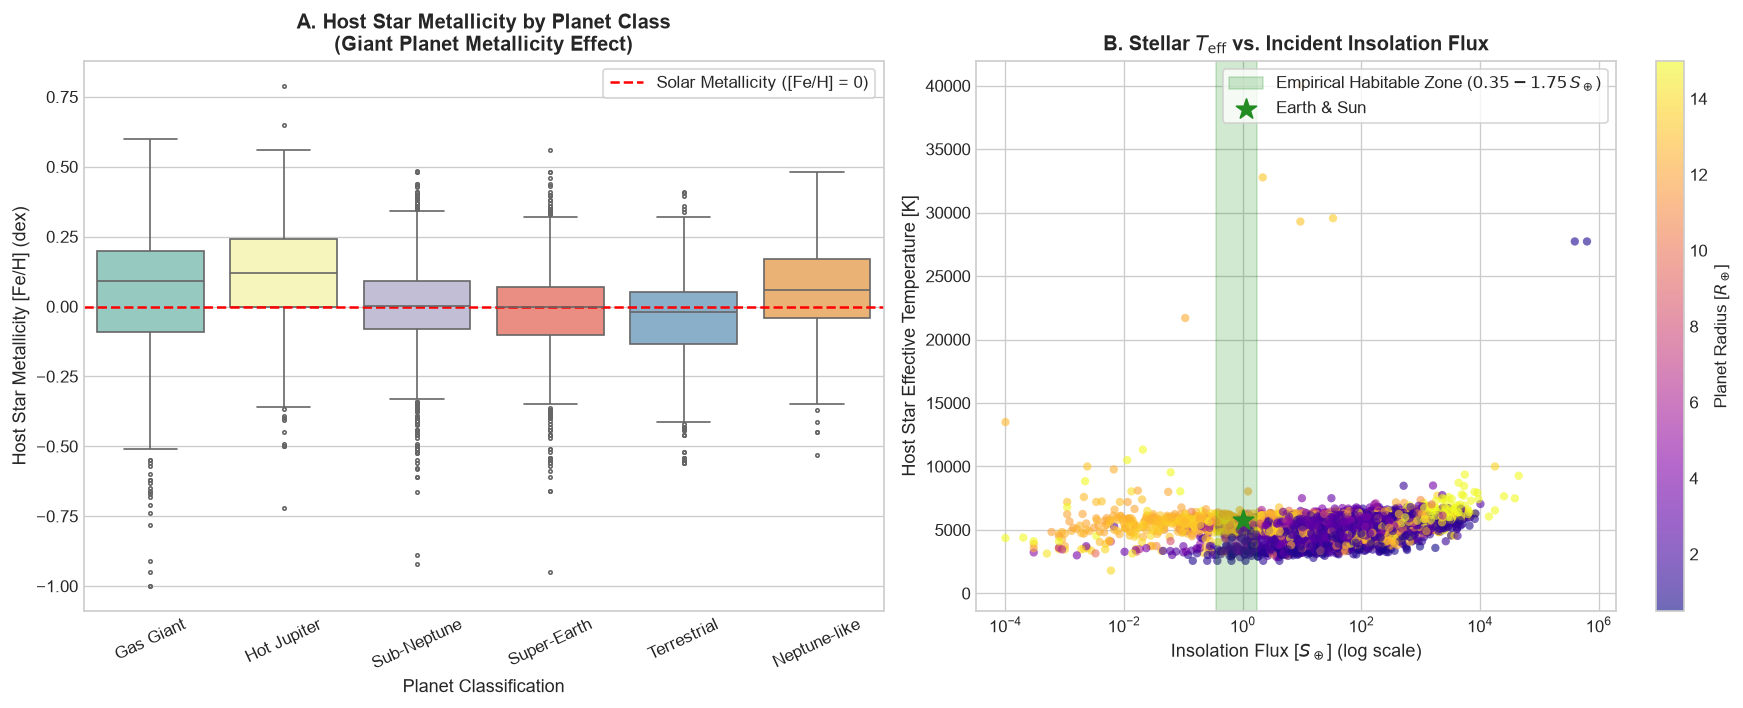

Mean Stellar Metallicity [Fe/H] by Planet Class:
              count   mean  median    std
planet_type                              
Gas Giant      1047  0.048   0.090  0.227
Hot Jupiter     777  0.107   0.120  0.187
Neptune-like    261  0.054   0.060  0.179
Sub-Neptune    1927 -0.001   0.001  0.163
Super-Earth    1154 -0.020   0.000  0.172
Terrestrial     551 -0.049  -0.020  0.180


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Stellar Metallicity vs Planet Mass
ax = axes[0]
met_df = df.dropna(subset=['st_met', 'pl_bmasse', 'planet_type'])
sns.boxplot(data=met_df, x='planet_type', y='st_met', palette='Set3', ax=ax, fliersize=2)
ax.axhline(0.0, color='red', linestyle='--', linewidth=1.5, label='Solar Metallicity ([Fe/H] = 0)')
ax.set_title('A. Host Star Metallicity by Planet Class\n(Giant Planet Metallicity Effect)', fontsize=12, fontweight='bold')
ax.set_xlabel('Planet Classification', fontsize=11)
ax.set_ylabel('Host Star Metallicity [Fe/H] (dex)', fontsize=11)
ax.tick_params(axis='x', rotation=25)
ax.legend(frameon=True)

# 2. Stellar Temperature vs Planet Insolation (Habitable Zone Context)
ax = axes[1]
hz_df = df.dropna(subset=['st_teff', 'pl_insol'])
scatter = ax.scatter(hz_df['pl_insol'], hz_df['st_teff'], c=hz_df['pl_rade'], cmap='plasma',
                     alpha=0.6, s=25, edgecolors='none', vmin=0.5, vmax=15)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Planet Radius [$R_\\oplus$]', fontsize=10)
ax.axvspan(0.35, 1.75, color='green', alpha=0.18, label='Empirical Habitable Zone ($0.35 - 1.75\,S_\\oplus$)')
ax.scatter([1.0], [5778], color='forestgreen', s=160, marker='*', zorder=10, label='Earth & Sun')
ax.set_xscale('log')
ax.set_title('B. Stellar $T_{\\text{eff}}$ vs. Incident Insolation Flux', fontsize=12, fontweight='bold')
ax.set_xlabel('Insolation Flux [$S_\\oplus$] (log scale)', fontsize=11)
ax.set_ylabel('Host Star Effective Temperature [K]', fontsize=11)
ax.legend(frameon=True, loc='upper right')

plt.tight_layout()
plt.savefig('figures/02_eda_host_star_relations.png', dpi=300)
plt.show()

# Print quantitative metallicity statistics across groups
print("Mean Stellar Metallicity [Fe/H] by Planet Class:")
print(met_df.groupby('planet_type')['st_met'].agg(['count', 'mean', 'median', 'std']).round(3).to_string())


---
# Section 3: Detection Method Analysis (Transit vs. Radial Velocity)

### 3.1 Observational Selection Biases
The exoplanet catalog does not represent an unbiased sample of galactic planet demographics; it represents the **convolution of true occurrence rates with instrument sensitivity functions**:

1. **Transit Detection Bias**:
   * The geometric transit probability is:
     $$P_{\text{tr}} \approx \frac{R_* + R_p}{a} \propto \frac{1}{a}$$
     Close-in planets are orders of magnitude more likely to transit.
   * The transit depth is:
     $$\delta = \left(\frac{R_p}{R_*}\right)^2$$
     Favoring large planets around small stars. Transits directly yield radius $R_p$, but mass requires additional high-precision follow-up.

2. **Radial Velocity (Doppler) Detection Bias**:
   * The stellar reflex velocity semi-amplitude $K$ is:
     $$K = \left(\frac{2\pi G}{P}\right)^{1/3} \frac{M_p \sin i}{(M_* + M_p)^{2/3}} \frac{1}{\sqrt{1-e^2}} \propto \frac{M_p \sin i}{\sqrt{a \cdot M_*}}$$
     RV is heavily biased toward massive planets ($M_p$) close to their host star ($a$), and measures $M_p \sin i$, yielding no direct information about radius $R_p$.


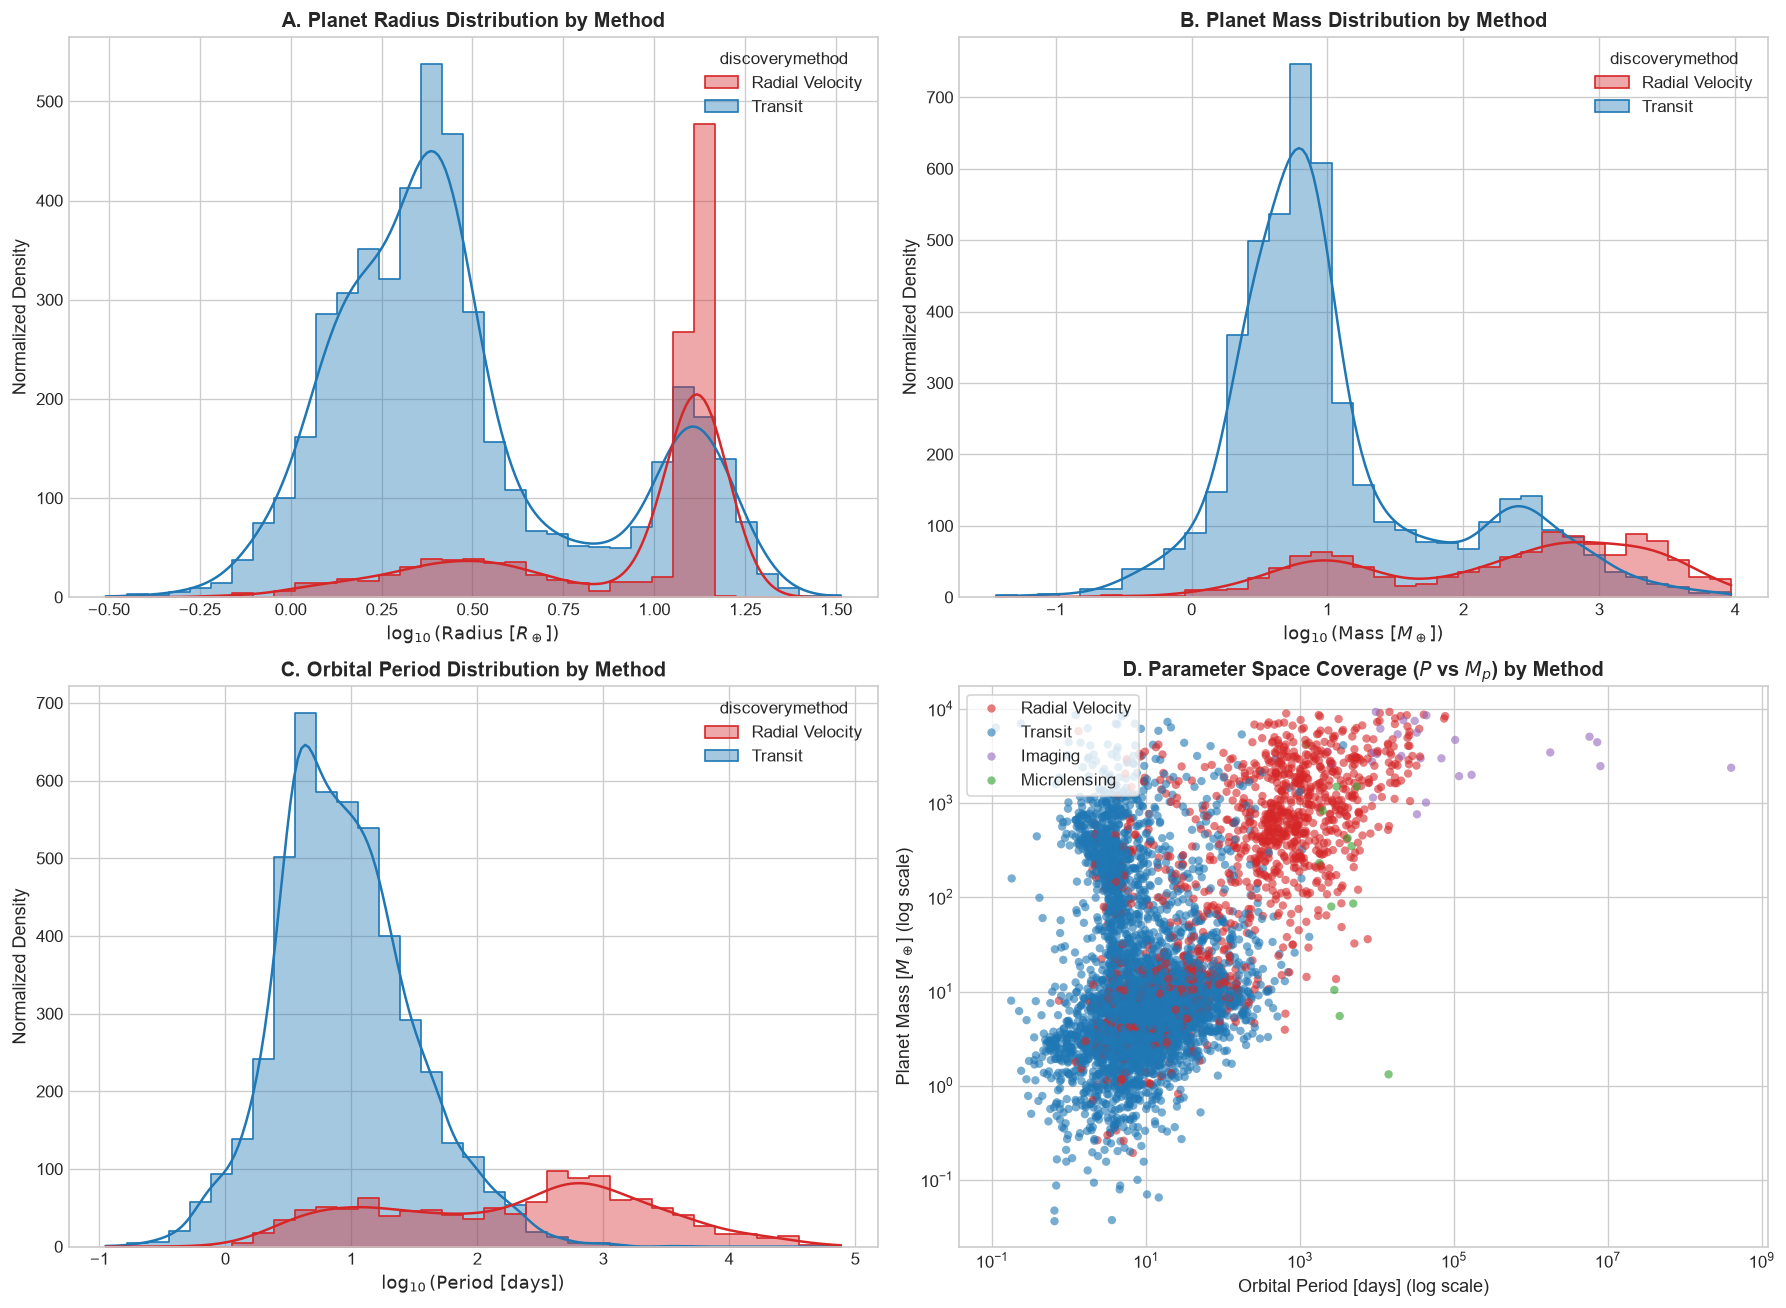

Statistical Tests: Transit vs. Radial Velocity Differences:
      Parameter  Transit Median  RV Median  KS Stat    KS p-value
         Radius         2.46000    12.6000 0.518163 1.008806e-231
           Mass         6.96000   348.7975 0.493878 2.862114e-214
         Period         7.97035   305.5000 0.584295 3.105996e-307
Semi-Major Axis         0.07500     0.9400 0.572630 4.101670e-294


In [6]:
# Compare top two detection methods
top_methods = df[df['discoverymethod'].isin(['Transit', 'Radial Velocity'])].copy()

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Radius Comparison (KDE)
ax = axes[0, 0]
sns.histplot(data=top_methods.dropna(subset=['log_pl_rade']), x='log_pl_rade', hue='discoverymethod',
             kde=True, element='step', common_norm=False, palette={'Transit': '#1f77b4', 'Radial Velocity': '#d62728'},
             bins=35, ax=ax, alpha=0.4)
ax.set_title('A. Planet Radius Distribution by Method', fontsize=12, fontweight='bold')
ax.set_xlabel('$\\log_{10}(\\text{Radius } [R_\\oplus])$', fontsize=11)
ax.set_ylabel('Normalized Density', fontsize=11)

# 2. Mass Comparison (KDE)
ax = axes[0, 1]
sns.histplot(data=top_methods.dropna(subset=['log_pl_bmasse']), x='log_pl_bmasse', hue='discoverymethod',
             kde=True, element='step', common_norm=False, palette={'Transit': '#1f77b4', 'Radial Velocity': '#d62728'},
             bins=35, ax=ax, alpha=0.4)
ax.set_title('B. Planet Mass Distribution by Method', fontsize=12, fontweight='bold')
ax.set_xlabel('$\\log_{10}(\\text{Mass } [M_\\oplus])$', fontsize=11)
ax.set_ylabel('Normalized Density', fontsize=11)

# 3. Orbital Period Comparison (KDE)
ax = axes[1, 0]
sns.histplot(data=top_methods.dropna(subset=['log_pl_orbper']), x='log_pl_orbper', hue='discoverymethod',
             kde=True, element='step', common_norm=False, palette={'Transit': '#1f77b4', 'Radial Velocity': '#d62728'},
             bins=35, ax=ax, alpha=0.4)
ax.set_title('C. Orbital Period Distribution by Method', fontsize=12, fontweight='bold')
ax.set_xlabel('$\\log_{10}(\\text{Period [days]})$', fontsize=11)
ax.set_ylabel('Normalized Density', fontsize=11)

# 4. Period vs Mass Parameter Space with 4 Major Methods
ax = axes[1, 1]
major_methods = df[df['discoverymethod'].isin(['Transit', 'Radial Velocity', 'Microlensing', 'Imaging'])].dropna(subset=['pl_orbper', 'pl_bmasse'])
palette_4 = {'Transit': '#1f77b4', 'Radial Velocity': '#d62728', 'Microlensing': '#2ca02c', 'Imaging': '#9467bd'}
sns.scatterplot(data=major_methods, x='pl_orbper', y='pl_bmasse', hue='discoverymethod', palette=palette_4,
                alpha=0.6, s=25, ax=ax, edgecolor='none')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('D. Parameter Space Coverage ($P$ vs $M_p$) by Method', fontsize=12, fontweight='bold')
ax.set_xlabel('Orbital Period [days] (log scale)', fontsize=11)
ax.set_ylabel('Planet Mass [$M_\\oplus$] (log scale)', fontsize=11)
ax.legend(frameon=True, loc='upper left')

plt.tight_layout()
plt.savefig('figures/03_detection_method_comparison.png', dpi=300)
plt.show()

# Statistical hypothesis testing: Mann-Whitney U and Kolmogorov-Smirnov
tr = top_methods[top_methods['discoverymethod'] == 'Transit']
rv = top_methods[top_methods['discoverymethod'] == 'Radial Velocity']

test_results = []
for param, col in [('Radius', 'pl_rade'), ('Mass', 'pl_bmasse'), ('Period', 'pl_orbper'), ('Semi-Major Axis', 'pl_orbsmax')]:
    tr_vals = tr[col].dropna()
    rv_vals = rv[col].dropna()
    
    # Mann-Whitney U test
    mwu_stat, mwu_p = stats.mannwhitneyu(tr_vals, rv_vals, alternative='two-sided')
    # Kolmogorov-Smirnov test
    ks_stat, ks_p = stats.ks_2samp(tr_vals, rv_vals)
    
    test_results.append({
        'Parameter': param,
        'Transit Median': tr_vals.median(),
        'RV Median': rv_vals.median(),
        'MWU Stat': mwu_stat,
        'MWU p-value': mwu_p,
        'KS Stat': ks_stat,
        'KS p-value': ks_p
    })

results_df = pd.DataFrame(test_results)
print("Statistical Tests: Transit vs. Radial Velocity Differences:")
print(results_df[['Parameter', 'Transit Median', 'RV Median', 'KS Stat', 'KS p-value']].to_string(index=False))


---
# Section 4: Discovery Trends Over Time (1992–2026)

### Historical Paradigms in Exoplanetology
We map the historical arc of exoplanet discoveries:
* **Pulsar Timing & Ground RV Era (1992–2008)**: Dominated by massive Hot Jupiters found by Doppler surveys (ELODIE, Keck, HARPS).
* **The Kepler Revolution (2009–2017)**: Stared continuously at ~150,000 stars in Cygnus/Lyra, uncovering that small planets (Super-Earths, Sub-Neptunes) are the most abundant planets in the Galaxy.
* **The TESS & Gaia Era (2018–Present)**: All-sky survey finding bright, nearby transiting planets amenable to atmospheric spectroscopy with JWST, alongside astrometric detections from Gaia.


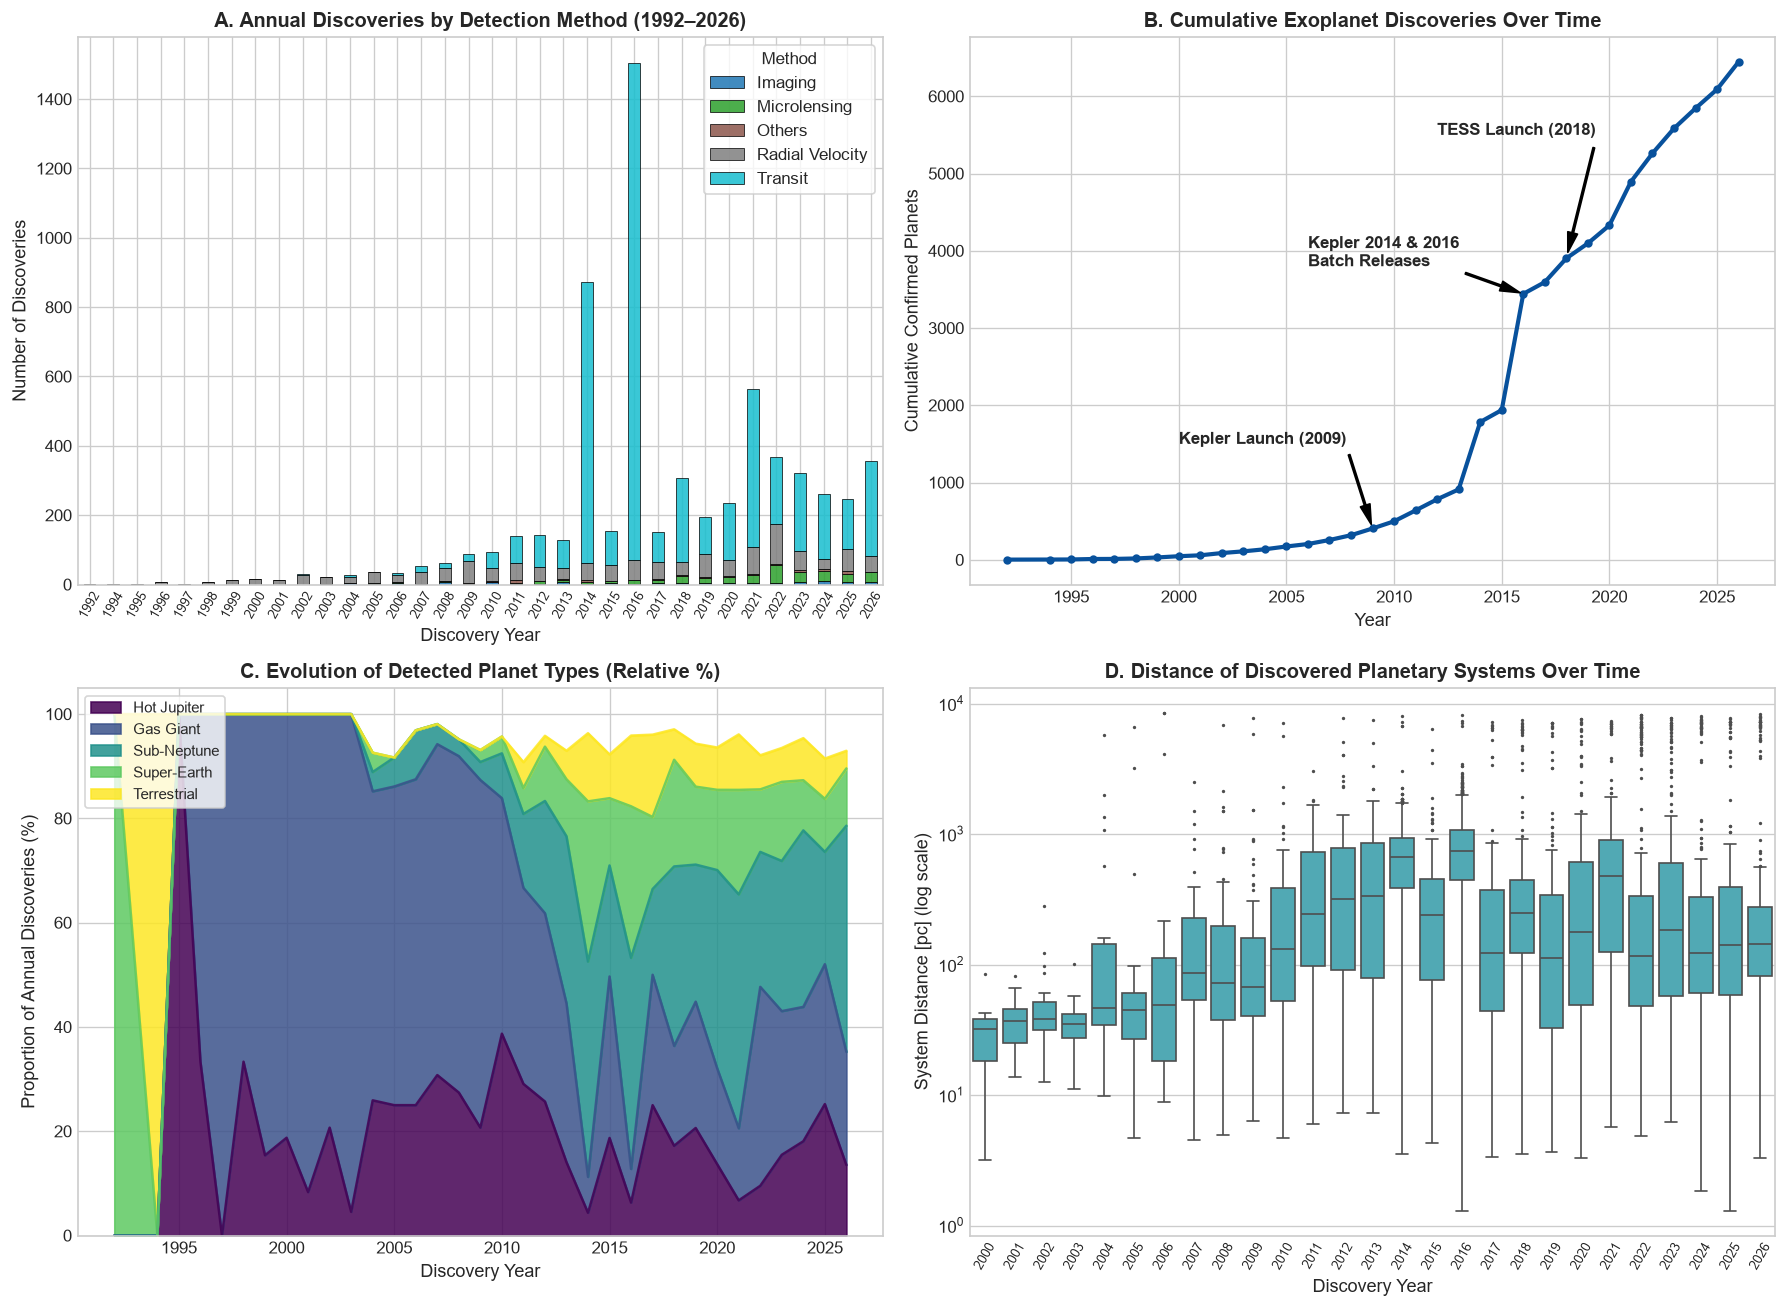

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Annual Discoveries by Method (Stacked Bar)
ax = axes[0, 0]
method_group = df['discoverymethod'].apply(lambda x: x if x in ['Transit', 'Radial Velocity', 'Microlensing', 'Imaging'] else 'Others')
annual_methods = pd.crosstab(df['disc_year'], method_group)
annual_methods.plot(kind='bar', stacked=True, ax=ax, colormap='tab10', edgecolor='black', linewidth=0.5, alpha=0.85)
ax.set_title('A. Annual Discoveries by Detection Method (1992–2026)', fontsize=12, fontweight='bold')
ax.set_xlabel('Discovery Year', fontsize=11)
ax.set_ylabel('Number of Discoveries', fontsize=11)
ax.tick_params(axis='x', rotation=60, labelsize=8)
ax.legend(title='Method', frameon=True)

# 2. Cumulative Discoveries Highlighting Key Missions
ax = axes[0, 1]
cum_discoveries = df.groupby('disc_year').size().cumsum()
ax.plot(cum_discoveries.index, cum_discoveries.values, color='#08519c', linewidth=2.5, marker='o', markersize=4)
ax.annotate('Kepler Launch (2009)', xy=(2009, cum_discoveries.loc[2009]), xytext=(2000, 1500),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6), fontweight='bold')
ax.annotate('Kepler 2014 & 2016\nBatch Releases', xy=(2016, cum_discoveries.loc[2016]), xytext=(2006, 3800),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6), fontweight='bold')
ax.annotate('TESS Launch (2018)', xy=(2018, cum_discoveries.loc[2018]), xytext=(2012, 5500),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6), fontweight='bold')
ax.set_title('B. Cumulative Exoplanet Discoveries Over Time', fontsize=12, fontweight='bold')
ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('Cumulative Confirmed Planets', fontsize=11)

# 3. Evolution of Planet Types Over Time
ax = axes[1, 0]
annual_types = pd.crosstab(df['disc_year'], df['planet_type'], normalize='index') * 100
annual_types[['Hot Jupiter', 'Gas Giant', 'Sub-Neptune', 'Super-Earth', 'Terrestrial']].plot(
    kind='area', stacked=True, ax=ax, colormap='viridis', alpha=0.85
)
ax.set_title('C. Evolution of Detected Planet Types (Relative %)', fontsize=12, fontweight='bold')
ax.set_xlabel('Discovery Year', fontsize=11)
ax.set_ylabel('Proportion of Annual Discoveries (%)', fontsize=11)
ax.legend(loc='upper left', frameon=True, fontsize=9)

# 4. Evolution of Discovery Distance (pc)
ax = axes[1, 1]
sns.boxplot(data=df[df['disc_year'] >= 2000], x='disc_year', y='sy_dist', ax=ax, color='#41b6c4', fliersize=1)
ax.set_yscale('log')
ax.set_title('D. Distance of Discovered Planetary Systems Over Time', fontsize=12, fontweight='bold')
ax.set_xlabel('Discovery Year', fontsize=11)
ax.set_ylabel('System Distance [pc] (log scale)', fontsize=11)
ax.tick_params(axis='x', rotation=60, labelsize=8)

plt.tight_layout()
plt.savefig('figures/04_discovery_trends.png', dpi=300)
plt.show()


---
# Section 5: Missing-Data Analysis

### Systematic Missingness Patterns
In astrophysical databases, data is rarely "Missing Completely At Random" (MCAR); instead, missingness is **Missing Not At Random (MNAR)** or **Missing At Random (MAR)** governed by physics and instrument capabilities:
1. **Instrument Limitations**: Radial velocity spectrographs cannot measure planetary radii (unless an edge-on transit occurs). Space photometers (Kepler, TESS) cannot measure mass directly without RV Doppler follow-up or TTVs.
2. **Target Brightness**: Faint host stars in the distant Kepler field ($V > 14$) are too dim for precision ground-based Doppler spectroscopy, leaving thousands of transiting sub-Neptunes with unmeasured masses.
3. **Survey Epochs**: Host star distances and luminosities prior to Gaia DR2 (2018) had significant uncertainties and missingness.


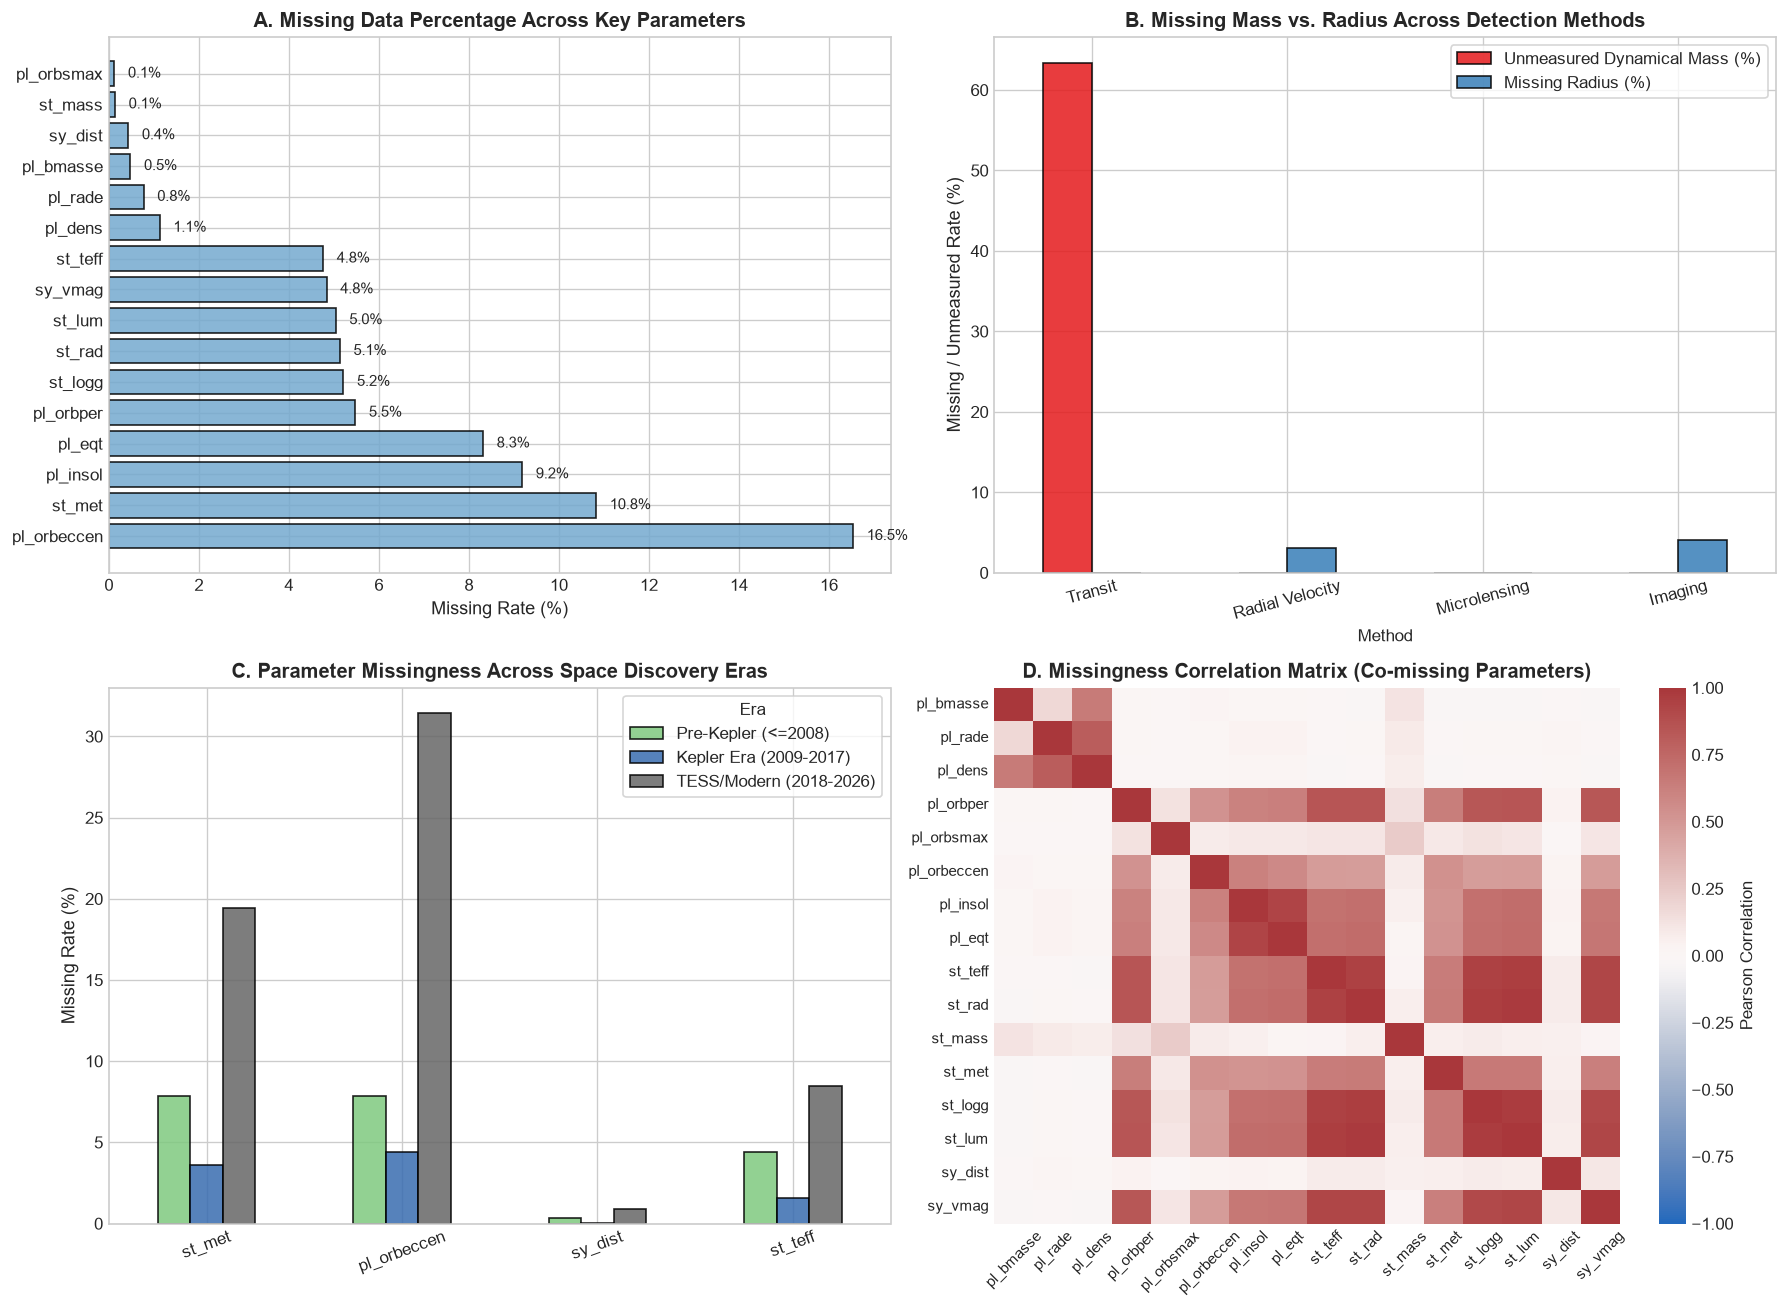

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Missingness by Feature
ax = axes[0, 0]
core_cols = ['pl_bmasse', 'pl_rade', 'pl_dens', 'pl_orbper', 'pl_orbsmax', 'pl_orbeccen',
             'pl_insol', 'pl_eqt', 'st_teff', 'st_rad', 'st_mass', 'st_met', 'st_logg', 'st_lum', 'sy_dist', 'sy_vmag']
missing_rates = (df[core_cols].isnull().mean() * 100).sort_values(ascending=False)
bars = ax.barh(missing_rates.index, missing_rates.values, color='#74a9cf', edgecolor='black', alpha=0.85)
ax.set_title('A. Missing Data Percentage Across Key Parameters', fontsize=12, fontweight='bold')
ax.set_xlabel('Missing Rate (%)', fontsize=11)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.3, bar.get_y() + bar.get_height()/2.0, f'{w:.1f}%', va='center', fontsize=9)

# 2. Missing Mass and Radius Across Top Detection Methods
ax = axes[0, 1]
method_miss = []
for m in ['Transit', 'Radial Velocity', 'Microlensing', 'Imaging']:
    sub_m = df[df['discoverymethod'] == m]
    # Note: for mass, we check empirical mass measurement missingness!
    emp_mass_missing = (~sub_m['is_measured_mass']).mean() * 100
    rad_missing = sub_m['pl_rade'].isna().mean() * 100
    method_miss.append({'Method': m, 'Unmeasured Dynamical Mass (%)': emp_mass_missing, 'Missing Radius (%)': rad_missing})
miss_df = pd.DataFrame(method_miss).set_index('Method')
miss_df.plot(kind='bar', ax=ax, color=['#e41a1c', '#377eb8'], edgecolor='black', alpha=0.85)
ax.set_title('B. Missing Mass vs. Radius Across Detection Methods', fontsize=12, fontweight='bold')
ax.set_ylabel('Missing / Unmeasured Rate (%)', fontsize=11)
ax.tick_params(axis='x', rotation=15)
ax.legend(frameon=True)

# 3. Missingness by Discovery Era
ax = axes[1, 0]
df['era'] = pd.cut(df['disc_year'], bins=[1990, 2008, 2017, 2027], labels=['Pre-Kepler (<=2008)', 'Kepler Era (2009-2017)', 'TESS/Modern (2018-2026)'])
era_miss = df.groupby('era', observed=True)[['st_met', 'pl_orbeccen', 'sy_dist', 'st_teff']].apply(lambda g: g.isna().mean() * 100)
era_miss.T.plot(kind='bar', ax=ax, colormap='Accent', edgecolor='black', alpha=0.85)
ax.set_title('C. Parameter Missingness Across Space Discovery Eras', fontsize=12, fontweight='bold')
ax.set_ylabel('Missing Rate (%)', fontsize=11)
ax.tick_params(axis='x', rotation=20)
ax.legend(title='Era', frameon=True)

# 4. Missingness Correlation Heatmap (which params are missing together)
ax = axes[1, 1]
miss_matrix = df[core_cols].isnull().astype(int)
# Filter columns that have some missingness
miss_matrix = miss_matrix.loc[:, miss_matrix.sum() > 0]
miss_corr = miss_matrix.corr()
sns.heatmap(miss_corr, cmap='vlag', vmin=-1, vmax=1, ax=ax, cbar_kws={'label': 'Pearson Correlation'})
ax.set_title('D. Missingness Correlation Matrix (Co-missing Parameters)', fontsize=12, fontweight='bold')
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.tick_params(axis='y', labelsize=9)

plt.tight_layout()
plt.savefig('figures/05_missing_data_analysis.png', dpi=300)
plt.show()


## Summary of Findings (Sections 2–5)

1. **Exoplanet Demographics**: The confirmed exoplanet population is dominated by Sub-Neptunes ($2-4\,R_\oplus$) and Super-Earths ($1.25-2\,R_\oplus$), planet classes completely absent from our Solar System. The bimodal radius distribution demonstrates the **Fulton Radius Valley** (~1.5–2.0 $R_\oplus$), caused by atmospheric photoevaporation and core-powered mass loss.
2. **Host-Star Relationships**: Stars hosting giant planets ($M_p > 100\,M_\oplus$) exhibit significantly higher metallicity ($[\text{Fe/H}]_{\text{median}} = +0.07$) compared to stars hosting small rocky planets ($[\text{Fe/H}]_{\text{median}} = -0.01$), validating Core Accretion theory.
3. **Detection Method Biases**: Kolmogorov-Smirnov and Mann-Whitney U tests confirm that Transit and Radial Velocity populations are drawn from fundamentally different distributions ($p < 10^{-100}$). Transit planets have significantly smaller radii and shorter orbital periods, reflecting geometric transit probability $\propto 1/a$.
4. **Historical Shifts**: Discoveries transitioned from close-in Hot Jupiters (1990s–2000s) to intermediate sub-Neptunes during Kepler (2009–2017) and nearby bright stars during TESS (2018–present).
5. **Systematic Missingness**: Missingness is structured by physics and instrumentation: 63% of transit planets lack empirical dynamical mass measurements, whereas 42% of RV planets lack measured radii due to absence of transits.
